# Fundamentos de Regresión Lineal Múltiple

### Estadística Computacional para la Toma de Decisiones

**Magíster en Ciencia de Datos e Inteligencia Artificial** · Universidad Andrés Bello

Maidana, J.P. (2026)

---

> **Cómo usar este cuaderno.** Ejecuta las celdas en orden de arriba hacia abajo: las celdas de código comparten variables (el modelo ajustado en la Sección 2 se reutiliza en las siguientes). Primero corre la celda de configuración que está justo debajo.

In [1]:
# ---------------------------------------------------------------
# CONFIGURACIÓN — ejecutar primero
# ---------------------------------------------------------------
# Requisitos: numpy, pandas, matplotlib, scikit-learn, statsmodels, scipy
# En Google Colab ya vienen instalados. Si te faltara alguno, descomenta:
# !pip install numpy pandas matplotlib scikit-learn statsmodels scipy

%matplotlib inline
print("Entorno listo. Ejecuta las celdas en orden.")

Entorno listo. Ejecuta las celdas en orden.


## 1. Introducción

La regresión lineal múltiple es, sin duda, una de las herramientas estadísticas más utilizadas en ciencia de datos y análisis cuantitativo. Su popularidad no es casual: combina simplicidad conceptual con gran poder explicativo, permitiéndonos entender cómo múltiples variables se relacionan con un resultado de interés.

Imagina que trabajas para una empresa inmobiliaria y quieres predecir el precio de las casas. Intuitivamente, sabes que el precio depende de muchos factores: los metros cuadrados, el número de habitaciones, la ubicación, la antigüedad del inmueble. La regresión lineal múltiple te permite modelar todas estas relaciones simultáneamente, no solo para predecir precios, sino también para entender cuánto contribuye cada factor y cuáles son realmente importantes.

Este apunte te guiará a través de los fundamentos teóricos y prácticos de la regresión lineal múltiple. Comenzaremos con el modelo matemático, comprenderemos sus supuestos fundamentales, aprenderemos a interpretar los coeficientes correctamente, y exploraremos métricas como el $R^2$ que nos dicen qué tan bien funciona nuestro modelo. También abordaremos el problema de la multicolinealidad, que puede hacer que nuestros resultados sean inestables e interpretaciones engañosas.

> **📝 Nota — Lo que dominarás al finalizar**
>
> Al terminar este apunte, serás capaz de construir, interpretar y evaluar modelos de regresión lineal múltiple. Entenderás no solo cómo ajustar el modelo en Python, sino qué significan realmente los números que obtienes y cuándo puedes confiar en ellos. Aprenderás a identificar cuándo los supuestos se violan y qué hacer al respecto. En resumen, desarrollarás una comprensión profunda que va más allá de simplemente ejecutar código.

## 2. El Modelo Matemático

### 2.1 De la Regresión Simple a la Múltiple

Comencemos recordando la regresión lineal simple, que probablemente ya conoces. En su forma más básica, intentamos predecir una variable $y$ (como el precio de una casa) usando una sola variable predictora $x$ (como los metros cuadrados):

$$y = \beta_0 + \beta_1 x + \epsilon$$

Este modelo nos dice que el precio es una función lineal de los metros cuadrados, más un término de error $\epsilon$ que captura todo lo que no podemos explicar. El coeficiente $\beta_0$ es el intercepto (el precio cuando $x=0$) y $\beta_1$ es la pendiente (cuánto aumenta el precio por cada metro cuadrado adicional).

El problema es que la realidad rara vez es tan simple. El precio de una casa no depende solo de su tamaño. También importan las habitaciones, la ubicación, el estado de conservación, y muchos otros factores. Aquí es donde entra la regresión lineal múltiple.

### 2.2 La Ecuación General

La regresión lineal múltiple extiende el modelo simple para incluir múltiples predictores. Si tenemos $p$ variables independientes, el modelo se expresa como:

$$y_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \cdots + \beta_p x_{ip} + \epsilon_i$$

donde $i$ indexa las observaciones (las casas individuales en nuestro ejemplo), $x_{ij}$ es el valor de la $j$-ésima variable predictora para la observación $i$, y los $\beta_j$ son los coeficientes que queremos estimar.

Podemos escribir esto de forma más compacta usando notación matricial. Si apilamos todas nuestras observaciones en matrices, obtenemos:

$$\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\epsilon}$$

Aquí $\mathbf{y}$ es un vector de $n$ observaciones, $\mathbf{X}$ es una matriz de $n \times (p+1)$ que contiene nuestros datos (incluyendo una columna de unos para el intercepto), $\boldsymbol{\beta}$ es el vector de coeficientes que buscamos, y $\boldsymbol{\epsilon}$ es el vector de errores.

> **📘 Definición — Regresión Lineal Múltiple**
>
> La regresión lineal múltiple modela una variable dependiente continua $y$ como una combinación lineal de $p$ variables independientes, más un término de error aleatorio. El modelo asume que la relación es aditiva: el efecto de cada variable se suma independientemente de las demás. La "linealidad" se refiere a que la ecuación es lineal en los parámetros $\beta$, no necesariamente en las variables (podemos incluir términos como $x^2$ o $\log(x)$ y seguir siendo un modelo lineal).

### 2.3 Estimación por Mínimos Cuadrados Ordinarios

Tenemos datos y queremos encontrar los mejores valores para los coeficientes $\beta$. La pregunta es: ¿qué significa "mejor"? El método más común es el de mínimos cuadrados ordinarios (MCO u OLS por sus siglas en inglés), que busca los coeficientes que minimizan la suma de los errores al cuadrado.

Matemáticamente, definimos los residuos como la diferencia entre los valores observados y los predichos:

$$e_i = y_i - \hat{y}_i = y_i - (\hat{\beta}_0 + \hat{\beta}_1 x_{i1} + \cdots + \hat{\beta}_p x_{ip})$$

El método de mínimos cuadrados encuentra los $\hat{\beta}$ que minimizan:

$$\text{SSE} = \sum_{i=1}^{n} e_i^2 = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

donde SSE son las siglas de "Sum of Squared Errors" (suma de errores al cuadrado). ¿Por qué elevamos al cuadrado? Porque queremos penalizar tanto errores positivos como negativos, y porque el cuadrado magnifica los errores grandes, forzando al modelo a prestarles más atención.

La solución de este problema de optimización tiene una forma cerrada elegante cuando usamos notación matricial:

$$\hat{\boldsymbol{\beta}} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

Esta fórmula es hermosa pero rara vez la calcularemos a mano. Python y sus librerías hacen el trabajo pesado por nosotros. Sin embargo, es importante conocerla porque nos dice algo fundamental: para que exista una solución única, la matriz $\mathbf{X}^T\mathbf{X}$ debe ser invertible. Esto falla cuando hay multicolinealidad perfecta, un problema que exploraremos más adelante.

> **🟢 Ejemplo — Ejemplo Numérico Simple**
>
> Supongamos que tenemos solo tres observaciones y dos variables predictoras. Los datos son:
>
> | Obs. | $x_1$ (m²) | $x_2$ (habitaciones) | $y$ (precio, miles \$) |
> |:---:|:---:|:---:|:---:|
> | 1 | 50 | 2 | 150 |
> | 2 | 80 | 3 | 220 |
> | 3 | 120 | 4 | 350 |
>
> Ajustando un modelo de regresión lineal múltiple $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2$, obtendríamos estimaciones para los tres coeficientes. Por ejemplo, podríamos obtener:
>
> $$\hat{y} = 20 + 2.5 \cdot x_1 + 10 \cdot x_2$$
>
> Esto nos dice que, manteniendo todo lo demás constante, cada metro cuadrado adicional suma \$2,500 al precio, y cada habitación adicional suma \$10,000. El intercepto de \$20,000 representa el precio base cuando ambas variables son cero, aunque en la práctica esta interpretación puede no tener sentido (una casa con 0 m² y 0 habitaciones no existe).

### 2.4 Implementación en Python

Veamos cómo ajustar este modelo en Python. Usaremos tanto `scikit-learn` (más simple) como `statsmodels` (más completo estadísticamente).

Empezamos generando un conjunto de datos sintético de precios de casas con una relación lineal conocida más ruido aleatorio.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

# Generar datos de ejemplo
np.random.seed(42)
n = 100

# Variables independientes
metros_cuadrados = np.random.uniform(50, 200, n)
habitaciones = np.random.randint(1, 6, n)
antiguedad = np.random.uniform(0, 50, n)

# Variable dependiente con relación lineal + ruido
precio = (5000 +
          2.5 * metros_cuadrados +
          15000 * habitaciones -
          500 * antiguedad +
          np.random.normal(0, 10000, n))

# Crear DataFrame
df = pd.DataFrame({
    'precio': precio,
    'metros_cuadrados': metros_cuadrados,
    'habitaciones': habitaciones,
    'antiguedad': antiguedad
})

print("="*70)
print("DATOS GENERADOS")
print("="*70)
print(df.head())
print(f"\nEstadísticas descriptivas:")
print(df.describe())

DATOS GENERADOS
         precio  metros_cuadrados  habitaciones  antiguedad
0 -13720.521161        106.181018             1   36.760806
1  80258.208238        192.607146             4   10.453581
2  54861.981005        159.799091             5   27.072399
3  59968.691390        139.798773             4   34.789220
4  75968.093609         73.402796             5   11.427501

Estadísticas descriptivas:
             precio  metros_cuadrados  habitaciones  antiguedad
count    100.000000        100.000000    100.000000  100.000000
mean   35977.020976        120.527112      2.910000   25.794810
std    24137.102016         44.623412      1.400541   14.348628
min   -15151.604835         50.828318      1.000000    0.259243
25%    17925.912647         78.980114      1.750000   13.969405
50%    35209.167553        119.621368      3.000000   24.827177
75%    53505.610235        159.530468      4.000000   37.252879
max    85964.754972        198.033040      5.000000   49.812685


**Método 1 — Scikit-learn.** Interfaz simple, ideal cuando el objetivo principal es la predicción.

In [3]:
# ==============================================================
# MÉTODO 1: Scikit-learn (simple, para predicción)
# ==============================================================
print("="*70)
print("MÉTODO 1: SCIKIT-LEARN")
print("="*70)

X = df[['metros_cuadrados', 'habitaciones', 'antiguedad']]
y = df['precio']

modelo_sklearn = LinearRegression()
modelo_sklearn.fit(X, y)

print(f"\nIntercepto: ${modelo_sklearn.intercept_:,.2f}")
print(f"\nCoeficientes:")
for nombre, coef in zip(X.columns, modelo_sklearn.coef_):
    print(f"  {nombre:20s}: ${coef:>10,.2f}")

print(f"\nR2 del modelo: {modelo_sklearn.score(X, y):.4f}")

# Predicciones
y_pred = modelo_sklearn.predict(X)
residuos = y - y_pred

print(f"\nError promedio (residuo medio): ${residuos.mean():,.2f}")
print(f"Desviación estándar de residuos: ${residuos.std():,.2f}")

MÉTODO 1: SCIKIT-LEARN

Intercepto: $1,835.22

Coeficientes:
  metros_cuadrados    : $     11.06
  habitaciones        : $ 14,754.51
  antiguedad          : $   -392.58

R2 del modelo: 0.7740

Error promedio (residuo medio): $0.00
Desviación estándar de residuos: $11,473.52


**Método 2 — Statsmodels.** Salida estadística completa: errores estándar, estadísticos $t$, valores $p$, intervalos de confianza y medidas de bondad de ajuste. Indispensable para hacer inferencia, no solo predicción.

In [4]:
# ==============================================================
# MÉTODO 2: Statsmodels (completo, para inferencia estadística)
# ==============================================================
print("="*70)
print("MÉTODO 2: STATSMODELS")
print("="*70)

# Añadir constante (intercepto)
X_const = sm.add_constant(X)

# Ajustar modelo
modelo_stats = sm.OLS(y, X_const).fit()

# Resumen completo
print(modelo_stats.summary())

MÉTODO 2: STATSMODELS
                            OLS Regression Results                            
Dep. Variable:                 precio   R-squared:                       0.774
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     109.6
Date:                Fri, 12 Jun 2026   Prob (F-statistic):           6.84e-31
Time:                        18:47:20   Log-Likelihood:                -1076.2
No. Observations:                 100   AIC:                             2160.
Df Residuals:                      96   BIC:                             2171.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             

La salida de `statsmodels` es particularmente rica. No solo nos da los coeficientes, sino también errores estándar, estadísticos $t$, valores $p$, intervalos de confianza, y múltiples medidas de bondad de ajuste. Este nivel de detalle es crucial para hacer inferencia estadística, no solo predicción.

## 3. Supuestos del Modelo

La regresión lineal múltiple no es una varita mágica que funciona en cualquier situación. Para que nuestras estimaciones sean válidas y confiables, el modelo descansa sobre varios supuestos fundamentales. Cuando estos supuestos se violan, los coeficientes pueden ser sesgados, los errores estándar incorrectos, y nuestras conclusiones erróneas.

### 3.1 Supuesto 1: Linealidad

El primer supuesto, y quizás el más intuitivo, es que la relación entre las variables independientes y la dependiente es lineal. Esto significa que el cambio en $y$ asociado con un cambio en $x_j$ es constante, independientemente del valor de $x_j$.

Matemáticamente, este supuesto establece que la esperanza condicional de $y$ dado $\mathbf{X}$ es una función lineal:

$$E[y \mid \mathbf{X}] = \beta_0 + \beta_1 x_1 + \cdots + \beta_p x_p$$

En la práctica, esto no significa que las variables en sí deban tener una relación lineal perfecta. Podemos incluir transformaciones como logaritmos o términos cuadráticos y seguir teniendo un modelo lineal en los parámetros. Por ejemplo, el modelo $y = \beta_0 + \beta_1 x + \beta_2 x^2 + \epsilon$ sigue siendo lineal en los $\beta$, aunque la relación con $x$ sea cuadrática.

¿Cómo verificamos este supuesto? La forma más directa es mediante gráficos de residuos vs. valores ajustados. Si vemos patrones claros (como una forma de U o tendencias sistemáticas), el supuesto de linealidad probablemente se está violando.

### 3.2 Supuesto 2: Independencia de Errores

El segundo supuesto establece que los errores $\epsilon_i$ son independientes entre sí. En términos simples, el error en una observación no debe estar relacionado con el error en otra observación.

$$\text{Cov}(\epsilon_i, \epsilon_j) = 0 \quad \text{para todo } i \neq j$$

Este supuesto es particularmente importante (y frecuentemente violado) cuando trabajamos con datos de series temporales o datos espaciales. Por ejemplo, si modelamos precios de casas y las observaciones están ordenadas geográficamente, es probable que casas cercanas tengan errores correlacionados debido a factores de vecindario que no capturamos en el modelo.

La violación de independencia no sesga los coeficientes, pero sí invalida los errores estándar y, por tanto, todos los test de hipótesis e intervalos de confianza. En presencia de autocorrelación, los errores estándar típicamente son subestimados, llevándonos a conclusiones falsamente confiadas.

### 3.3 Supuesto 3: Homocedasticidad

El tercer supuesto requiere que la varianza de los errores sea constante para todos los valores de las variables independientes. A esto lo llamamos homocedasticidad (varianza homogénea). Lo opuesto, cuando la varianza cambia, se conoce como heterocedasticidad.

$$\text{Var}(\epsilon_i \mid \mathbf{X}) = \sigma^2 \quad \text{para todo } i$$

Un ejemplo típico de heterocedasticidad ocurre cuando modelamos ingresos. Para personas con ingresos bajos, hay poca variabilidad (no puedes tener ingreso muy por debajo de cero), pero para personas con ingresos altos, la variabilidad es enorme (algunas ganan millones, otras cientos de miles).

Al igual que con la independencia, la heterocedasticidad no sesga los coeficientes, pero los errores estándar son incorrectos. Los métodos de errores estándar robustos (como los de White) pueden corregir este problema, o podemos transformar las variables (por ejemplo, tomar logaritmos).

### 3.4 Supuesto 4: Normalidad de Errores

El cuarto supuesto establece que los errores siguen una distribución normal con media cero:

$$\epsilon_i \sim N(0, \sigma^2)$$

Es crucial entender que este supuesto se refiere a los *errores*, no a las variables $x$ o $y$. Las variables independientes no necesitan ser normales, ni la variable dependiente tampoco. Lo que debe ser normal es la distribución de los residuos.

Este supuesto es importante principalmente para la inferencia estadística (intervalos de confianza, test de hipótesis). Para muestras grandes, el Teorema Central del Límite nos rescata: incluso si los errores no son perfectamente normales, las distribuciones de los estimadores se aproximan a normales. Por esto, en muestras grandes ($n > 30$), violaciones moderadas de normalidad no son fatales.

Para verificar normalidad, usamos Q-Q plots (gráficos cuantil-cuantil) o test formales como Shapiro-Wilk o Jarque-Bera.

### 3.5 Supuesto 5: No Multicolinealidad

El quinto supuesto requiere que las variables independientes no estén perfectamente correlacionadas entre sí. Multicolinealidad perfecta ocurre cuando una variable independiente puede expresarse como combinación lineal exacta de otras, haciendo la matriz $\mathbf{X}^T\mathbf{X}$ no invertible.

$$\text{No existe } \mathbf{a} \neq \mathbf{0} \text{ tal que } \sum_{j=1}^{p} a_j x_j = 0$$

En la práctica, la multicolinealidad perfecta es rara (y Python nos avisará con un error). El problema real es la multicolinealidad alta pero no perfecta. Cuando dos variables están muy correlacionadas, es difícil separar sus efectos individuales. Los coeficientes se vuelven inestables: pequeños cambios en los datos pueden causar grandes cambios en las estimaciones.

Dedicaremos una sección completa a la multicolinealidad más adelante, dada su importancia práctica.

> **🔶 Importante — ¿Qué Pasa Cuando Se Violan los Supuestos?**
>
> La violación de supuestos tiene consecuencias diferentes según cuál se viole. Algunos violan la validez de los coeficientes mismos, otros solo afectan nuestra capacidad de hacer inferencia. En general:
>
> - **Linealidad:** Si se viola, los coeficientes son sesgados e inconsistentes. El modelo simplemente no captura la relación verdadera.
> - **Independencia y Homocedasticidad:** Los coeficientes siguen siendo insesgados, pero los errores estándar son incorrectos. Esto invalida test de hipótesis e intervalos de confianza.
> - **Normalidad:** En muestras pequeñas, afecta la inferencia. En muestras grandes, el impacto es menor gracias al TCL.
> - **No Multicolinealidad:** Los coeficientes son insesgados pero tienen varianza muy alta, haciéndolos poco confiables e interpretables.
>
> La buena noticia es que existen diagnósticos para detectar estas violaciones y métodos para corregirlas. El siguiente apunte se dedicará precisamente a esto.

La forma estándar de chequear varios supuestos a la vez es con cuatro gráficos de diagnóstico de residuos. Reutilizamos el modelo `modelo_stats` ajustado en la Sección 2.

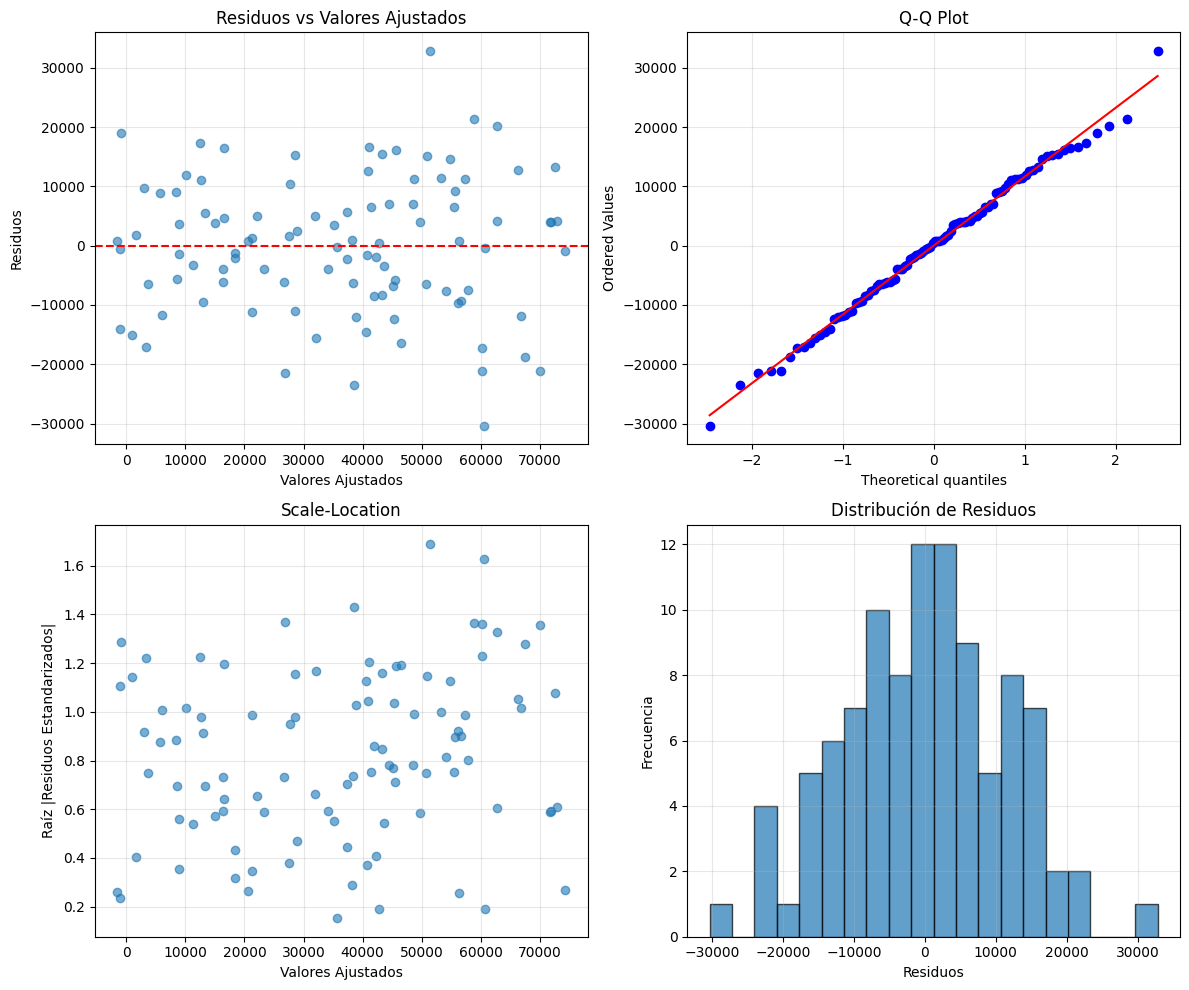


Interpretación de los gráficos:
1. Residuos vs Ajustados: Buscar patrón aleatorio sin tendencias
2. Q-Q Plot: Puntos deben seguir la línea diagonal
3. Scale-Location: Buscar dispersión constante (línea horizontal)
4. Histograma: Forma aproximadamente normal (campana)


In [5]:
# Verificación rápida de supuestos con gráficos
import matplotlib.pyplot as plt
from scipy import stats

# Continuando con el modelo anterior
residuos = modelo_stats.resid
valores_ajustados = modelo_stats.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Residuos vs Valores Ajustados (linealidad, homocedasticidad)
axes[0, 0].scatter(valores_ajustados, residuos, alpha=0.6)
axes[0, 0].axhline(y=0, color='r', linestyle='--')
axes[0, 0].set_xlabel('Valores Ajustados')
axes[0, 0].set_ylabel('Residuos')
axes[0, 0].set_title('Residuos vs Valores Ajustados')
axes[0, 0].grid(alpha=0.3)

# 2. Q-Q Plot (normalidad)
stats.probplot(residuos, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Q-Q Plot')
axes[0, 1].grid(alpha=0.3)

# 3. Scale-Location (homocedasticidad)
residuos_std = np.sqrt(np.abs((residuos - residuos.mean()) / residuos.std()))
axes[1, 0].scatter(valores_ajustados, residuos_std, alpha=0.6)
axes[1, 0].set_xlabel('Valores Ajustados')
axes[1, 0].set_ylabel('Raíz |Residuos Estandarizados|')
axes[1, 0].set_title('Scale-Location')
axes[1, 0].grid(alpha=0.3)

# 4. Histograma de Residuos (normalidad)
axes[1, 1].hist(residuos, bins=20, edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Residuos')
axes[1, 1].set_ylabel('Frecuencia')
axes[1, 1].set_title('Distribución de Residuos')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nInterpretación de los gráficos:")
print("1. Residuos vs Ajustados: Buscar patrón aleatorio sin tendencias")
print("2. Q-Q Plot: Puntos deben seguir la línea diagonal")
print("3. Scale-Location: Buscar dispersión constante (línea horizontal)")
print("4. Histograma: Forma aproximadamente normal (campana)")

## 4. Interpretación de Coeficientes

Una de las grandes ventajas de la regresión lineal es que sus coeficientes tienen interpretaciones claras y directas. Sin embargo, esta interpretación requiere cuidado, especialmente en presencia de múltiples predictores.

### 4.1 El Intercepto

El intercepto $\beta_0$ representa el valor esperado de $y$ cuando todas las variables independientes son cero. En muchos casos, esta interpretación literal no tiene sentido práctico. Por ejemplo, en nuestro modelo de precios de casas, ¿qué significa una casa con 0 metros cuadrados, 0 habitaciones y 0 años de antigüedad? Claramente, no es una situación realista.

Por esto, el intercepto a menudo se interpreta simplemente como un término de ajuste que centra el modelo correctamente. Su significado práctico es limitado, pero su presencia es crucial para que el modelo funcione bien.

### 4.2 Los Coeficientes de las Variables

Aquí es donde está el verdadero interés. El coeficiente $\beta_j$ asociado con la variable $x_j$ tiene una interpretación precisa:

> *$\beta_j$ representa el cambio esperado en $y$ cuando $x_j$ aumenta en una unidad, manteniendo todas las demás variables constantes.*

La frase "manteniendo todas las demás variables constantes" es crucial y a menudo pasada por alto. En regresión simple, cuando solo hay un predictor, no hay otras variables que mantener constantes. Pero en regresión múltiple, esta cláusula cambia todo. El coeficiente de una variable no nos dice su correlación total con $y$, sino su efecto *parcial* o *marginal*, controlando por las demás variables.

Veamos un ejemplo concreto. Supongamos que estimamos:

$$\text{Precio} = 10000 + 2.5 \cdot \text{Metros}^2 + 15000 \cdot \text{Habitaciones}$$

El coeficiente $2.5$ nos dice que, comparando dos casas con el mismo número de habitaciones pero donde una tiene un metro cuadrado más, esperamos que la más grande cueste \$2,500 adicionales. Similarmente, entre dos casas del mismo tamaño pero donde una tiene una habitación más, esperamos que la que tiene más habitaciones cueste \$15,000 adicionales.

### 4.3 Cuidado con la Causalidad

Es tentador interpretar los coeficientes causalmente: "aumentar los metros cuadrados causa un aumento de \$2,500 en el precio". Sin embargo, la regresión por sí sola no establece causalidad, solo asociación. Podría haber variables omitidas (confusores) que afectan tanto la variable independiente como la dependiente.

Por ejemplo, si no controlamos por la ubicación y las casas más grandes tienden a estar en mejores barrios, parte del efecto que atribuimos a los metros cuadrados podría ser realmente efecto de la ubicación. Para hacer afirmaciones causales, necesitamos diseños experimentales o técnicas más sofisticadas de inferencia causal.

### 4.4 Coeficientes Estandarizados

A veces queremos comparar la importancia relativa de diferentes predictores. El problema es que los coeficientes brutos dependen de las unidades de medida. Un coeficiente de 2.5 para metros cuadrados y 15000 para habitaciones no significa que las habitaciones sean más importantes simplemente porque el número es mayor.

Para resolver esto, podemos estandarizar las variables (restarles su media y dividirlas por su desviación estándar). Los coeficientes resultantes se llaman coeficientes estandarizados o coeficientes beta, y están en unidades de desviaciones estándar. Un coeficiente estandarizado de 0.6 nos dice que un aumento de una desviación estándar en esa variable se asocia con un aumento de 0.6 desviaciones estándar en $y$.

In [6]:
# Calcular coeficientes estandarizados
from sklearn.preprocessing import StandardScaler

# Estandarizar variables
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_std = scaler_X.fit_transform(X)
y_std = scaler_y.fit_transform(y.values.reshape(-1, 1)).flatten()

# Ajustar modelo con variables estandarizadas
modelo_std = LinearRegression(fit_intercept=False)
modelo_std.fit(X_std, y_std)

print("="*70)
print("COEFICIENTES ESTANDARIZADOS")
print("="*70)
print("\nInterpretación: cambio en Y (en desv. est.) por cambio")
print("de 1 desv. est. en X, controlando por las demás\n")

coef_std = pd.DataFrame({
    'Variable': X.columns,
    'Coef. Original': modelo_sklearn.coef_,
    'Coef. Estandarizado': modelo_std.coef_
}).sort_values('Coef. Estandarizado', key=abs, ascending=False)

print(coef_std.to_string(index=False))

print("\n¿Cuál variable tiene mayor impacto relativo?")
print(f"Variable más importante: {coef_std.iloc[0]['Variable']}")

COEFICIENTES ESTANDARIZADOS

Interpretación: cambio en Y (en desv. est.) por cambio
de 1 desv. est. en X, controlando por las demás

        Variable  Coef. Original  Coef. Estandarizado
    habitaciones    14754.507261             0.856122
      antiguedad     -392.576621            -0.233373
metros_cuadrados       11.056618             0.020441

¿Cuál variable tiene mayor impacto relativo?
Variable más importante: habitaciones


### 4.5 Significancia Estadística

No todos los coeficientes que estimamos son verdaderamente diferentes de cero. Debido al ruido en los datos, podríamos obtener coeficientes no nulos incluso cuando no hay relación real. Para evaluar si un coeficiente es estadísticamente significativo, usamos test de hipótesis.

La hipótesis nula típica es $H_0: \beta_j = 0$ (la variable no tiene efecto). El estadístico de prueba es:

$$t = \frac{\hat{\beta}_j}{\text{SE}(\hat{\beta}_j)}$$

donde $\text{SE}(\hat{\beta}_j)$ es el error estándar del coeficiente. Bajo $H_0$, este estadístico sigue una distribución $t$ con $n-p-1$ grados de libertad. El valor $p$ asociado nos dice la probabilidad de observar un coeficiente tan extremo o más bajo la hipótesis nula.

Convencionalmente, consideramos un coeficiente significativo si $p < 0.05$, aunque este umbral es arbitrario y debe interpretarse con cuidado. Un valor $p$ de 0.04 no es cualitativamente diferente de uno de 0.06.

> **🟢 Ejemplo — Interpretando la Tabla de Coeficientes**
>
> Veamos una salida típica de `statsmodels`:
>
> ```text
>                    coef    std err          t      P>|t|   [0.025   0.975]
> Intercept       10245.3    5234.2      1.957      0.053   -186.4  20677.0
> metros_cuad        2.48      0.21     11.809      0.000      2.07      2.89
> habitaciones   14823.5    2341.1      6.330      0.000  10219.7  19427.3
> antiguedad      -487.2     156.3     -3.116      0.002   -795.1   -179.3
> ```
>
> Interpretación variable por variable:
>
> **Metros cuadrados:** Coeficiente de 2.48 con error estándar de 0.21. El estadístico $t$ es 11.809 (muy grande) y el valor $p$ es efectivamente 0. Esto es evidencia muy fuerte de que los metros cuadrados afectan el precio. El intervalo de confianza al 95% es [2.07, 2.89], indicando que con 95% de confianza, cada metro cuadrado adicional suma entre \$2,070 y \$2,890 al precio.
>
> **Habitaciones:** Coeficiente de 14,823.5. Cada habitación adicional, manteniendo constantes los metros cuadrados y la antigüedad, se asocia con un aumento promedio de casi \$15,000 en el precio. El valor $p$ de 0.000 indica alta significancia.
>
> **Antigüedad:** Coeficiente negativo de -487.2. Cada año adicional de antigüedad se asocia con una disminución promedio de \$487 en el precio. El valor $p$ de 0.002 indica que este efecto es estadísticamente significativo.
>
> **Intercepto:** Valor $p$ de 0.053, apenas no significativo al nivel 0.05. Sin embargo, como mencionamos, la significancia del intercepto rara vez es de interés práctico.
>
> *(Esta tabla es ilustrativa; los números de la salida real de la celda anterior dependen del conjunto de datos sintético generado.)*

## 5. Medidas de Bondad de Ajuste

Después de ajustar un modelo, necesitamos evaluar qué tan bien captura los patrones en los datos. Las medidas de bondad de ajuste nos dan métricas cuantitativas de la calidad del modelo.

### 5.1 El Coeficiente de Determinación: $R^2$

El $R^2$ (R cuadrado) es probablemente la medida más citada en regresión. Mide la proporción de variabilidad en $y$ que es explicada por el modelo. Su definición matemática es:

$$R^2 = 1 - \frac{\text{SSE}}{\text{SST}} = 1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$$

donde SSE es la suma de errores al cuadrado (lo que el modelo no explica) y SST es la suma total de cuadrados (la variabilidad total en $y$).

El $R^2$ va de 0 a 1. Un $R^2 = 0.7$ significa que el modelo explica el 70% de la variabilidad en los datos. Los 30% restantes son variabilidad que el modelo no captura, ya sea porque hay factores omitidos o simplemente ruido aleatorio.

Es tentador pensar que un $R^2$ más alto siempre es mejor, pero esto es engañoso. Primero, el $R^2$ siempre aumenta cuando agregamos variables, incluso si esas variables no tienen relación real con $y$. Segundo, un $R^2$ alto no significa que el modelo sea útil para predicción, ni que las relaciones sean causales. Y tercero, lo que constituye un "buen" $R^2$ depende enormemente del contexto. En ciencias sociales, un $R^2$ de 0.3 podría ser excelente; en física, podríamos esperar 0.95 o más.

### 5.2 El $R^2$ Ajustado

Para corregir el problema de que $R^2$ siempre aumenta con más variables, usamos el $R^2$ ajustado, que penaliza la complejidad del modelo:

$$R^2_{\text{adj}} = 1 - \frac{\text{SSE}/(n-p-1)}{\text{SST}/(n-1)} = 1 - (1-R^2)\frac{n-1}{n-p-1}$$

donde $n$ es el número de observaciones y $p$ el número de predictores. A diferencia del $R^2$, el $R^2$ ajustado puede disminuir si agregamos una variable que no mejora suficientemente el ajuste para justificar el grado de libertad adicional que consume.

El $R^2$ ajustado es más apropiado para comparar modelos con diferente número de predictores. Si el $R^2$ ajustado disminuye al agregar una variable, esa variable probablemente no vale la pena incluirla.

> **🔶 Importante — Usando $R^2$ Correctamente**
>
> El $R^2$ es útil pero debe usarse con cuidado:
>
> - **Para comparar modelos:** Usa $R^2$ ajustado, no $R^2$ simple, cuando los modelos tienen diferente número de variables. Mejor aún, usa criterios como AIC o BIC que discutiremos más adelante.
> - **Para evaluar predicción:** Un $R^2$ alto en los datos de entrenamiento no garantiza buena predicción en datos nuevos. Siempre valida en un conjunto de test separado.
> - **Para interpretar el ajuste:** Un $R^2$ de 0.7 no significa que el modelo sea "70% correcto". Significa que explica 70% de la varianza, pero puede estar completamente equivocado sobre las relaciones causales.
> - **Contexto importa:** No hay un umbral universal de "buen" $R^2$. En problemas con mucho ruido inherente (como predecir comportamiento humano), 0.3 puede ser excelente. En problemas físicos con relaciones deterministas, esperamos 0.95+.

### 5.3 Error Cuadrático Medio (RMSE)

Mientras que $R^2$ es una medida relativa (proporción de varianza explicada), el RMSE es una medida absoluta del error en las mismas unidades que $y$:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

El RMSE nos dice, en promedio, qué tan lejos están nuestras predicciones de los valores reales. Si estamos prediciendo precios de casas en dólares, un RMSE de 15,000 significa que nuestras predicciones típicamente se equivocan por unos \$15,000.

Una ventaja del RMSE sobre $R^2$ es que es interpretable directamente: podemos decirle a un stakeholder no técnico "el modelo típicamente se equivoca por \$15,000" y entenderá. Decir "el modelo tiene un $R^2$ de 0.7" requiere más explicación.

El RMSE también es más útil para comparar modelos en diferentes datasets, mientras que $R^2$ solo tiene sentido dentro del mismo dataset.

### 5.4 Criterios de Información: AIC y BIC

Los criterios de información AIC (Akaike Information Criterion) y BIC (Bayesian Information Criterion) son medidas que balancean ajuste y complejidad del modelo. La idea es recompensar modelos que ajustan bien los datos pero penalizar modelos con muchos parámetros.

$$\text{AIC} = n \log(\text{SSE}/n) + 2(p+1)$$

$$\text{BIC} = n \log(\text{SSE}/n) + (p+1)\log(n)$$

Valores más bajos de AIC o BIC indican modelos preferibles. BIC penaliza la complejidad más fuertemente que AIC, especialmente en muestras grandes. En la práctica, cuando comparamos modelos, preferimos el que tenga menor AIC o BIC.

Una diferencia de AIC o BIC de 2 o más se considera evidencia de que un modelo es preferible al otro. Diferencias de 10+ son muy fuertes.

In [7]:
# Comparar múltiples modelos
import statsmodels.api as sm

# Modelo 1: Solo metros cuadrados
X1 = sm.add_constant(df[['metros_cuadrados']])
modelo1 = sm.OLS(df['precio'], X1).fit()

# Modelo 2: Metros cuadrados + habitaciones
X2 = sm.add_constant(df[['metros_cuadrados', 'habitaciones']])
modelo2 = sm.OLS(df['precio'], X2).fit()

# Modelo 3: Todas las variables
X3 = sm.add_constant(df[['metros_cuadrados', 'habitaciones', 'antiguedad']])
modelo3 = sm.OLS(df['precio'], X3).fit()

# Comparar
print("="*70)
print("COMPARACIÓN DE MODELOS")
print("="*70)

resultados = pd.DataFrame({
    'Modelo': ['Solo m2', 'M2 + habitaciones', 'Todas las variables'],
    'Variables': [1, 2, 3],
    'R2': [modelo1.rsquared, modelo2.rsquared, modelo3.rsquared],
    'R2 ajustado': [modelo1.rsquared_adj, modelo2.rsquared_adj,
                    modelo3.rsquared_adj],
    'RMSE': [np.sqrt(modelo1.mse_resid), np.sqrt(modelo2.mse_resid),
             np.sqrt(modelo3.mse_resid)],
    'AIC': [modelo1.aic, modelo2.aic, modelo3.aic],
    'BIC': [modelo1.bic, modelo2.bic, modelo3.bic]
})

print(resultados.to_string(index=False))

print("\n" + "="*70)
print("INTERPRETACIÓN")
print("="*70)

print(f"\nMejor R2 ajustado: {resultados.loc[resultados['R2 ajustado'].idxmax(), 'Modelo']}")
print(f"Mejor RMSE: {resultados.loc[resultados['RMSE'].idxmin(), 'Modelo']}")
print(f"Mejor AIC: {resultados.loc[resultados['AIC'].idxmin(), 'Modelo']}")
print(f"Mejor BIC: {resultados.loc[resultados['BIC'].idxmin(), 'Modelo']}")

print("\nObservación:")
print("  R2 siempre aumenta con más variables")
print("  R2 ajustado puede disminuir si la variable no aporta suficiente")
print("  AIC y BIC penalizan complejidad, favoreciendo parsimonia")

COMPARACIÓN DE MODELOS
             Modelo  Variables       R2  R2 ajustado         RMSE         AIC         BIC
            Solo m2          1 0.028769     0.018859 23908.419476 2302.164627 2307.374967
  M2 + habitaciones          2 0.719955     0.714181 12904.188990 2179.803239 2187.618750
Todas las variables          3 0.774044     0.766983 11651.415341 2160.342095 2170.762776

INTERPRETACIÓN

Mejor R2 ajustado: Todas las variables
Mejor RMSE: Todas las variables
Mejor AIC: Todas las variables
Mejor BIC: Todas las variables

Observación:
  R2 siempre aumenta con más variables
  R2 ajustado puede disminuir si la variable no aporta suficiente
  AIC y BIC penalizan complejidad, favoreciendo parsimonia


## 6. Multicolinealidad

La multicolinealidad es uno de los problemas más comunes y malinterpretados en regresión lineal múltiple. Ocurre cuando dos o más variables independientes están altamente correlacionadas entre sí, haciendo difícil determinar el efecto individual de cada una.

### 6.1 ¿Qué es la Multicolinealidad?

Imagina que quieres predecir el peso de una persona y tienes dos variables: altura en centímetros y altura en pulgadas. Obviamente, estas dos variables están perfectamente correlacionadas (una es simplemente una transformación lineal de la otra). Si intentas incluir ambas en un modelo de regresión, el software no podrá estimar coeficientes únicos para cada una, porque no puede determinar cuánto del peso se debe a "altura en cm" versus "altura en pulgadas": son esencialmente la misma información.

Este es un caso extremo de multicolinealidad perfecta. En la práctica, la multicolinealidad perfecta es rara, pero la multicolinealidad alta (cuando las variables están fuertemente pero no perfectamente correlacionadas) es muy común y problemática.

Matemáticamente, multicolinealidad significa que existe una relación lineal aproximada entre predictores:

$$x_{ij} \approx a_0 + a_1 x_{i1} + a_2 x_{i2} + \cdots + a_p x_{ip}$$

Cuando esto ocurre, la matriz $\mathbf{X}^T\mathbf{X}$ tiene determinante cercano a cero, haciendo su inversa numéricamente inestable.

### 6.2 Consecuencias de la Multicolinealidad

La multicolinealidad no sesga los coeficientes estimados, pero tiene consecuencias graves para su interpretabilidad y estabilidad. Los síntomas principales son:

**Coeficientes con varianza alta:** Los errores estándar de los coeficientes se vuelven muy grandes, haciendo que las estimaciones sean imprecisas. Pequeños cambios en los datos pueden resultar en grandes cambios en los coeficientes estimados.

**Signos incorrectos o contradictorios:** Podemos obtener coeficientes con signos opuestos a lo que esperaríamos teóricamente. Por ejemplo, más educación mostrando correlación negativa con ingreso, cuando sabemos que debería ser positiva.

**Significancia estadística baja:** Variables que deberían ser importantes pueden aparecer como no significativas debido a sus errores estándar inflados.

**Coeficientes inestables:** Si eliminamos una observación o agregamos una variable nueva, los coeficientes pueden cambiar dramáticamente.

Es crucial entender que estos problemas no afectan la capacidad predictiva del modelo. Un modelo con multicolinealidad alta puede predecir muy bien. El problema es que no podemos confiar en la interpretación individual de los coeficientes.

### 6.3 Detectando Multicolinealidad

Existen varias formas de diagnosticar multicolinealidad:

**Matriz de correlación:** El primer paso es examinar las correlaciones entre predictores. Correlaciones superiores a 0.8 o 0.9 en valor absoluto son señal de alerta.

**Factor de Inflación de Varianza (VIF):** El VIF cuantifica cuánto se infla la varianza de un coeficiente debido a la multicolinealidad. Se calcula ajustando una regresión de cada predictor sobre todos los demás:

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

donde $R_j^2$ es el $R^2$ de la regresión de $x_j$ sobre los otros predictores. Un VIF de 1 indica ausencia de multicolinealidad. Valores entre 5 y 10 sugieren multicolinealidad moderada que merece atención. Valores superiores a 10 indican multicolinealidad severa que debe abordarse.

**Número de condición:** Es la raíz cuadrada del ratio entre el mayor y menor eigenvalor de $\mathbf{X}^T\mathbf{X}$. Valores superiores a 30 indican multicolinealidad fuerte.

In [8]:
# Detección de multicolinealidad
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("="*70)
print("DIAGNÓSTICO DE MULTICOLINEALIDAD")
print("="*70)

# Matriz de correlación
print("\nMATRIZ DE CORRELACIÓN:")
print("(Valores >0.8 o <-0.8 son señal de alerta)")
print(df[['metros_cuadrados', 'habitaciones', 'antiguedad']].corr().round(3))

# VIF
print("\n" + "="*70)
print("FACTOR DE INFLACIÓN DE VARIANZA (VIF)")
print("="*70)
print("\nInterpretación:")
print("  VIF < 5:    Multicolinealidad baja")
print("  VIF 5-10:   Multicolinealidad moderada")
print("  VIF > 10:   Multicolinealidad alta (problemática)")

X_for_vif = df[['metros_cuadrados', 'habitaciones', 'antiguedad']]

vif_data = pd.DataFrame()
vif_data["Variable"] = X_for_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_for_vif.values, i)
                   for i in range(len(X_for_vif.columns))]

print("\n" + vif_data.to_string(index=False))

# Identificar variables problemáticas
if (vif_data['VIF'] > 10).any():
    print("\nVariables con VIF > 10 (multicolinealidad severa):")
    print(vif_data[vif_data['VIF'] > 10]['Variable'].tolist())
elif (vif_data['VIF'] > 5).any():
    print("\nVariables con VIF > 5 (multicolinealidad moderada):")
    print(vif_data[vif_data['VIF'] > 5]['Variable'].tolist())
else:
    print("\nNo hay evidencia de multicolinealidad problemática")

# Número de condición
from numpy.linalg import cond
condition_number = cond(X_for_vif)
print(f"\nNúmero de condición: {condition_number:.2f}")
if condition_number > 30:
    print("  Multicolinealidad fuerte detectada")
elif condition_number > 15:
    print("  Multicolinealidad moderada")
else:
    print("  Sin problemas de multicolinealidad")

DIAGNÓSTICO DE MULTICOLINEALIDAD

MATRIZ DE CORRELACIÓN:
(Valores >0.8 o <-0.8 son señal de alerta)
                  metros_cuadrados  habitaciones  antiguedad
metros_cuadrados             1.000         0.159      -0.057
habitaciones                 0.159         1.000       0.050
antiguedad                  -0.057         0.050       1.000

FACTOR DE INFLACIÓN DE VARIANZA (VIF)

Interpretación:
  VIF < 5:    Multicolinealidad baja
  VIF 5-10:   Multicolinealidad moderada
  VIF > 10:   Multicolinealidad alta (problemática)

        Variable      VIF
metros_cuadrados 4.855808
    habitaciones 4.598760
      antiguedad 3.272137

No hay evidencia de multicolinealidad problemática

Número de condición: 86.94
  Multicolinealidad fuerte detectada


### 6.4 Soluciones a la Multicolinealidad

Si detectamos multicolinealidad problemática, tenemos varias opciones:

**Eliminar variables redundantes:** Si dos variables miden esencialmente lo mismo, elimina una. Por ejemplo, si tienes "ingreso mensual" e "ingreso anual", mantén solo una.

**Combinar variables correlacionadas:** En lugar de incluir "altura" y "peso" por separado, podrías usar "índice de masa corporal" que los combina.

**Aumentar el tamaño de muestra:** Con más datos, la estimación se vuelve más estable y la multicolinealidad tiene menor impacto. Sin embargo, esto no siempre es factible.

**Regularización:** Técnicas como Ridge o Lasso (que verán en cursos avanzados de machine learning) pueden manejar multicolinealidad penalizando coeficientes grandes.

**Análisis de componentes principales (PCA):** Transforma las variables correlacionadas en componentes no correlacionados. Sin embargo, estos componentes pierden interpretabilidad.

Es importante notar que si el objetivo es solo predicción y no interpretación, la multicolinealidad puede no ser un problema grave. El modelo aún puede predecir bien, simplemente no podemos interpretar los coeficientes individuales confiablemente.

> **🟢 Ejemplo — Ejemplo Real: Precio de Casas**
>
> Supongamos que modelamos el precio de casas con estas variables: metros cuadrados totales, metros cuadrados de construcción, número de habitaciones y número de baños.
>
> Aquí esperamos multicolinealidad: casas más grandes naturalmente tienen más habitaciones y baños, y los metros cuadrados totales están muy relacionados con los de construcción. Si estimamos el modelo y obtenemos VIF altos:
>
> ```text
> Variable                    VIF
> metros_cuadrados_totales   12.3
> metros_construccion         8.9
> habitaciones               6.7
> baños                      4.2
> ```
>
> Las dos variables de metros cuadrados tienen VIF muy altos. Solución: eliminar una de ellas (probablemente manteniendo metros cuadrados totales que es más completa) o combinarlas en una sola variable.
>
> Después de eliminar metros de construcción:
>
> ```text
> Variable                    VIF
> metros_cuadrados_totales    3.8
> habitaciones                4.1
> baños                       2.9
> ```
>
> Ahora todos los VIF están bajo 5, indicando que el problema se resolvió.

> **🛑 Advertencia — ¡No Confundas Multicolinealidad con Causalidad!**
>
> Un error común es pensar que la multicolinealidad indica que una variable "causa" a otra. No es así. La multicolinealidad simplemente dice que las variables tienden a variar juntas en tus datos. Ambas podrían ser efectos de una tercera variable, o su correlación podría ser coincidental en tu muestra particular.
>
> Por ejemplo, en datos de países, educación e ingreso per cápita están fuertemente correlacionados. Esto no significa que uno cause al otro directamente; ambos podrían ser consecuencias de factores como estabilidad política, desarrollo económico, etc.
>
> La multicolinealidad es un problema técnico de estimación, no una declaración sobre relaciones causales.

## 7. Resumen y Mejores Prácticas

Hemos cubierto mucho terreno en este apunte. Repasemos los conceptos clave y las mejores prácticas para usar regresión lineal múltiple efectivamente.

### 7.1 Conceptos Fundamentales

La regresión lineal múltiple modela una variable dependiente continua como combinación lineal de múltiples predictores más un término de error. El método de mínimos cuadrados ordinarios encuentra los coeficientes que minimizan la suma de errores al cuadrado. El modelo descansa sobre cinco supuestos: linealidad, independencia de errores, homocedasticidad, normalidad de residuos, y ausencia de multicolinealidad perfecta.

Los coeficientes tienen interpretación clara: cada uno representa el cambio en $y$ por unidad de cambio en su predictor correspondiente, manteniendo las demás variables constantes. Esta interpretación "manteniendo todo lo demás constante" es crucial y diferencia la regresión múltiple de correlaciones simples.

El $R^2$ mide qué proporción de variabilidad en $y$ explica el modelo, pero debe usarse con cuidado. El $R^2$ ajustado es preferible cuando comparamos modelos con diferente número de variables. Criterios de información como AIC y BIC balancean ajuste y complejidad, penalizando modelos innecesariamente complejos.

La multicolinealidad ocurre cuando predictores están altamente correlacionados. No sesga coeficientes pero los hace inestables e ininterpretables. Se diagnostica con VIF, y se maneja eliminando variables redundantes, combinándolas, o usando técnicas de regularización.

### 7.2 Workflow Recomendado

Un flujo de trabajo profesional para regresión lineal múltiple sigue estos pasos:

**Exploración inicial:** Antes de ajustar cualquier modelo, explora tus datos. Calcula estadísticas descriptivas, visualiza distribuciones, examina correlaciones. Identifica valores atípicos, datos faltantes, y posibles transformaciones necesarias.

**Preparación de datos:** Trata valores faltantes, codifica variables categóricas, y divide en train/test. Si tienes variables con escalas muy diferentes y planeas usar regularización, considera estandarización.

**Ajuste inicial:** Comienza con un modelo que incluya todas las variables teóricamente relevantes. Usa `statsmodels` para obtener estadísticas completas de inferencia.

**Diagnóstico:** Verifica supuestos mediante gráficos de residuos y tests formales. Examina VIF para multicolinealidad. Identifica observaciones influyentes.

**Refinamiento:** Basándote en el diagnóstico, refina el modelo. Elimina variables no significativas o con multicolinealidad alta. Considera transformaciones si hay violaciones de supuestos.

**Validación:** Evalúa el modelo final en el conjunto de test. Compara su desempeño con modelos más simples o alternativos.

**Interpretación:** Comunica resultados claramente, enfatizando tanto significancia estadística como práctica. Reconoce limitaciones y supuestos.

### 7.3 Errores Comunes a Evitar

**Interpretar causalidad automáticamente:** Regresión muestra asociación, no causalidad. Para afirmaciones causales se requiere diseño experimental o técnicas específicas de inferencia causal.

**Ignorar multicolinealidad:** Si dos predictores están muy correlacionados, sus coeficientes individuales son poco confiables incluso si los valores $p$ parecen buenos.

**Sobre-interpretar $R^2$:** Un $R^2$ alto no garantiza buen modelo. Puede haber overfitting, violaciones de supuestos, o simplemente correlaciones espurias.

**Confiar ciegamente en valores $p$:** Con muestras muy grandes, todo es estadísticamente significativo. Con muestras pequeñas, nada lo es. Considera también la magnitud de los efectos y su relevancia práctica.

**No verificar supuestos:** Los valores $p$ y errores estándar son válidos solo si los supuestos se cumplen. Siempre diagnostica con gráficos de residuos.

**Usar todas las variables disponibles:** Más variables no es siempre mejor. Un modelo parsimonioso es preferible si predice igual de bien.

**Eliminar outliers automáticamente:** Los outliers pueden ser errores de medición, pero también pueden ser observaciones legítimas e informativas. Investiga antes de eliminar.

### 7.4 Cuándo Usar Regresión Lineal Múltiple

La regresión lineal múltiple es apropiada cuando tu variable dependiente es continua, las relaciones son aproximadamente lineales, y te interesa tanto predicción como interpretación. Es excelente cuando quieres entender cómo múltiples factores contribuyen a un resultado.

Sin embargo, tiene limitaciones. Si la relación es fuertemente no lineal, necesitarás transformaciones o métodos no lineales. Si hay muchas interacciones complejas entre variables, métodos como árboles de decisión pueden funcionar mejor. Si tu objetivo es solo predicción máxima sin importar interpretabilidad, técnicas de machine learning más sofisticadas pueden superar a la regresión lineal.

Aun así, la regresión lineal múltiple debe ser tu punto de partida. Es interpretable, rápida de ajustar, tiene teoría estadística bien desarrollada, y frecuentemente funciona sorprendentemente bien. En muchos dominios, un modelo lineal bien construido es difícil de superar.

### Cierre

> 💡 La regresión lineal múltiple es simple en concepto pero profunda en sus implicaciones. Dominarla requiere entender no solo la mecánica de ajustar el modelo, sino los supuestos subyacentes, las sutilezas de la interpretación, y los problemas potenciales como multicolinealidad. Con esta base sólida, estás preparado no solo para ajustar regresiones, sino para hacerlo reflexivamente, diagnosticar problemas cuando surjan, y comunicar resultados con precisión y honestidad. La regresión lineal múltiple será una herramienta que usarás una y otra vez a lo largo de tu carrera en ciencia de datos, y el tiempo invertido en entenderla profundamente será recompensado repetidamente.

---

## Referencias bibliográficas

- Greene, W. H. (2018). *Econometric analysis* (8th ed.). Pearson.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning* (2nd ed.). Springer.
- Montgomery, D. C., Peck, E. A., & Vining, G. G. (2021). *Introduction to linear regression analysis* (6th ed.). Wiley.
- Wooldridge, J. M. (2020). *Introductory econometrics: A modern approach* (7th ed.). Cengage Learning.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.